# AI in Fluids - Week 3 Lab 1

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week03/AI_in_Fluids_Week3_Lab1_Maxwellian_Noise_ML_Student.ipynb)
## Maxwellian sampling, macroscopic moments, DSMC noise, and noisy ML labels

**Course story:** Week 1 represented a fluid by grid fields. Week 2 trained a neural-network surrogate. This notebook shows where kinetic/DSMC field data come from and why finite particle sampling creates an error floor for machine learning.

### Submission reminder
Submit the **completed notebook with visible outputs** and include all requested interpretation in the single **Week-3 PDF report**. The notebook alone is not a complete submission.

## Temperature: distinguish the estimator from the physical effect
The historical `T_hat` cell uses a centered sum divided by N. Because the same
sample estimates the mean velocity, iid fixed-N Maxwellian samples satisfy
E[T_hat]=(N−1)T/N. This is the maximum-likelihood variance estimator, not the
unbiased sample-variance estimator. For N=30 its expected deficit is 3.33%;
this is a conditional analytic result, not a measured cavity bias.

For independent stationary samples and N>1, use `T_unbiased=N*T_hat/(N-1)`.
In three dimensions the energy sum has 3(N−1) degrees of freedom. For N≤1,
temperature about an estimated mean is undefined. Increasing independent
repeats reduces variance but does not repair the original estimator's bias.
**Check:** velocities [(−1,0,0),(1,0,0)] have mean zero and squared-speed sum 2.
With m/kB=1, T_ML=1/3; T_unbiased=2/3. Explain why neither one finite draw
must equal the generating thermodynamic temperature.

## Learning objectives
By the end of this notebook you should be able to:

1. sample molecular velocities from a Maxwellian distribution;
2. estimate bulk velocity, temperature, pressure, and heat flux from particles;
3. demonstrate that sampling error decreases approximately as the inverse square root of the number of independent samples;
4. explain why a neural network trained on noisy DSMC labels learns the labels, not an inaccessible exact solution.

### Route, controls and expected evidence

This CPU lab has four distinct experiments: draw a distribution; recover its moments; measure estimator convergence over independent realizations; and fit a small neural surrogate to labels with two noise levels. A point in the sampling-error plot is an average over independent particle clouds, not a time history. A point in the slip-proxy plot is a separate prescribed Knudsen condition, not a DSMC cell.

| Control | Meaning | First controlled change | Diagnostic |
|---|---|---|---|
| `N_SAMPLE` | Molecules in the displayed equilibrium cloud | 5000 to 500 | Distribution shape and moment discrepancy |
| `T_TRUE`, `U_TRUE` | Temperature [K], three-component drift [m/s] | Double temperature, retain drift | Width grows by $\sqrt{2}$, center stays fixed |
| `N_VALUES`, `N_REPEATS` | Population per cloud, independent clouds per population | Double repeats only | Less scatter in estimated RMSE, no change in estimator bias |
| `HIDDEN_UNITS`, `ACTIVATION` | Layer widths and nonlinear function | One change at a time | Label fit and signed error against analytic teaching trend |
| `MLP_ALPHA`, `MAX_ITER` | Weight penalty, L-BFGS iteration cap | Change using a separate validation design | Underfit/overfit and optimizer warning |

Save the random seeds with the answer. The worked neural comparison has **fixed, predeclared settings**; its analytic evaluation curve is public, not an untouched blind test. If you tune a model, introduce separate validation conditions and freeze the choices before a new evaluation. Keep the original controlled comparison in your report.


## 0. Imports and reproducibility

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week03"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

np.set_printoptions(precision=5, suppress=True)
SEED = 12
rng = np.random.default_rng(SEED)
print("Random seed:", SEED)

Matplotlib is building the font cache; this may take a moment.


Random seed: 12


## 1. Maxwellian molecular velocities
For a monatomic equilibrium gas, each Cartesian molecular-velocity component is normally distributed. The component standard deviation is set by temperature and molecular mass. A bulk velocity shifts the center of the distribution but does not represent the thermal fluctuation itself.

In [2]:
K_B = 1.380649e-23                    # Boltzmann constant [J/K]
M_ARGON = 6.6335209e-26              # argon molecular mass [kg]


def sample_maxwellian(n_particles, temperature, bulk_velocity=(0.0, 0.0, 0.0), seed=None):
    """Sample 3-D molecular velocities from an equilibrium Maxwellian."""
    local_rng = np.random.default_rng(seed)
    bulk_velocity = np.asarray(bulk_velocity, dtype=float)
    sigma = np.sqrt(K_B * temperature / M_ARGON)
    return bulk_velocity + sigma * local_rng.standard_normal((n_particles, 3))


T_TRUE = 300.0                         # K
U_TRUE = np.array([100.0, 0.0, 0.0])  # m/s
N_SAMPLE = 5000

c = sample_maxwellian(N_SAMPLE, T_TRUE, U_TRUE, seed=SEED)
sigma_true = np.sqrt(K_B * T_TRUE / M_ARGON)
print(f"Thermal component standard deviation = {sigma_true:.2f} m/s")
print("Molecular velocity array shape:", c.shape)

Thermal component standard deviation = 249.88 m/s
Molecular velocity array shape: (5000, 3)


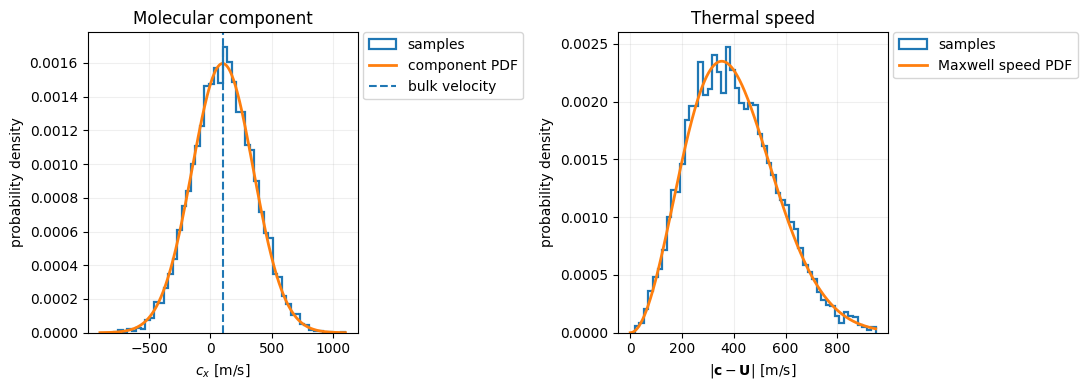

In [3]:
# Plot one velocity component and the thermal-speed distribution.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bins = np.linspace(U_TRUE[0] - 4*sigma_true, U_TRUE[0] + 4*sigma_true, 55)
axes[0].hist(c[:, 0], bins=bins, density=True, histtype="step", linewidth=1.6, label="samples")
x = np.linspace(bins[0], bins[-1], 400)
gaussian = np.exp(-0.5*((x-U_TRUE[0])/sigma_true)**2)/(sigma_true*np.sqrt(2*np.pi))
axes[0].plot(x, gaussian, lw=2, label="component PDF")
axes[0].axvline(U_TRUE[0], ls="--", lw=1.5, label="bulk velocity")
axes[0].set_xlabel(r"$c_x$ [m/s]")
axes[0].set_ylabel("probability density")
axes[0].set_title("Molecular component")
axes[0].legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
axes[0].grid(alpha=0.2)

thermal_speed = np.linalg.norm(c - U_TRUE, axis=1)
bins_s = np.linspace(0, np.percentile(thermal_speed, 99.8), 55)
axes[1].hist(thermal_speed, bins=bins_s, density=True, histtype="step", linewidth=1.6, label="samples")
s = np.linspace(0, bins_s[-1], 400)
maxwell_pdf = 4*np.pi*s**2*(M_ARGON/(2*np.pi*K_B*T_TRUE))**1.5 * np.exp(-M_ARGON*s**2/(2*K_B*T_TRUE))
axes[1].plot(s, maxwell_pdf, lw=2, label="Maxwell speed PDF")
axes[1].set_xlabel(r"$|\mathbf{c}-\mathbf{U}|$ [m/s]")
axes[1].set_ylabel("probability density")
axes[1].set_title("Thermal speed")
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Report prompt 1
Explain why the distribution width is much larger than the imposed bulk speed in this example. Distinguish molecular velocity from bulk velocity.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 2. Macroscopic quantities as particle moments

For $N$ velocities $\mathbf c_i$, define the sample drift $\widehat{\mathbf U}=N^{-1}\sum_i\mathbf c_i$ and thermal residual $\mathbf C_i=\mathbf c_i-\widehat{\mathbf U}$. The code evaluates

$$T_N=\frac{m}{3k_BN}\sum_i|\mathbf C_i|^2,\qquad p_N=n_0k_BT_N,\qquad \mathbf q_N=\frac{mn_0}{2N}\sum_i |\mathbf C_i|^2\mathbf C_i.$$

Here $m$ is the argon molecular mass, $k_B$ is Boltzmann's constant, and $n_0$ is number density [m$^{-3}$]. $T_N$, $p_N$ and $\mathbf q_N$ have units K, Pa and W/m$^2$. Subtracting the drift prevents organized motion from becoming spurious temperature. At equilibrium the exact heat-flux vector vanishes because odd thermal moments cancel; a finite sample does not cancel exactly. The norm of a noisy vector is nonnegative, so its average need not vanish.

The historical denominator $N$ is intentionally retained to expose finite-sample bias. For independent fixed-$N$ clouds, $T_{N-1}=NT_N/(N-1)$ is unbiased for $N>1$. This formula is not automatically valid for time-correlated or variably populated cavity cells.


In [4]:
def estimate_macroscopic_quantities(velocities, number_density, molecular_mass=M_ARGON):
    """Estimate monatomic-gas moments from a finite molecular sample."""
    U_hat = velocities.mean(axis=0)
    fluct = velocities - U_hat
    fluct2 = np.sum(fluct**2, axis=1)
    T_hat = molecular_mass * fluct2.mean() / (3.0 * K_B)
    p_hat = number_density * K_B * T_hat
    q_hat = 0.5 * molecular_mass * number_density * np.mean(fluct2[:, None] * fluct, axis=0)
    return U_hat, T_hat, p_hat, q_hat


N0 = 2.5e25  # illustrative argon number density [1/m^3]
U_hat, T_hat, p_hat, q_hat = estimate_macroscopic_quantities(c, N0)
q_scale = N0 * K_B * T_TRUE * sigma_true

summary = pd.DataFrame({
    "quantity": ["Ux [m/s]", "Uy [m/s]", "Uz [m/s]", "T [K]", "p [Pa]"],
    "imposed": [U_TRUE[0], U_TRUE[1], U_TRUE[2], T_TRUE, N0*K_B*T_TRUE],
    "estimated": [U_hat[0], U_hat[1], U_hat[2], T_hat, p_hat]
})
display(summary)
print("Estimated heat-flux vector [W/m^2]:", q_hat)
print("Normalized heat flux q/(n k_B T sigma):", q_hat/q_scale)

,quantity,imposed,estimated
0,Ux [m/s],100.000,106.752888
1,Uy [m/s],0.000,0.948188
2,Uz [m/s],0.000,3.761803
3,T [K],300.000,299.109064
4,p [Pa],103548.675,103241.157659


Estimated heat-flux vector [W/m^2]: [ 627130.64825 -629294.05333  340631.44236]
Normalized heat flux q/(n k_B T sigma): [ 0.02424 -0.02432  0.01316]


### Report prompt 2
Why is the bulk velocity subtracted before calculating temperature? Why is the sampled equilibrium heat flux not exactly zero?

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 3. Statistical noise versus number of particles

In [5]:
def repeated_sampling_errors(n_particles, repeats=200, seed=1):
    local_rng = np.random.default_rng(seed)
    u_errors = []
    t_errors = []
    t_unbiased_errors = []
    qstar_norms = []
    for _ in range(repeats):
        velocities = U_TRUE + sigma_true * local_rng.standard_normal((n_particles, 3))
        Ue, Te, _, qe = estimate_macroscopic_quantities(velocities, N0)
        u_errors.append(Ue[0] - U_TRUE[0])
        t_errors.append(Te - T_TRUE)
        t_unbiased_errors.append(n_particles*Te/(n_particles-1) - T_TRUE)
        qstar_norms.append(np.linalg.norm(qe/q_scale))
    return {
        "rmse_Ux": np.sqrt(np.mean(np.square(u_errors))),
        "rmse_T": np.sqrt(np.mean(np.square(t_errors))),
        "bias_T": float(np.mean(t_errors)),
        "rmse_T_unbiased": np.sqrt(np.mean(np.square(t_unbiased_errors))),
        "bias_T_unbiased": float(np.mean(t_unbiased_errors)),
        "mean_qstar_norm": np.mean(qstar_norms)
    }


N_VALUES = np.array([30, 60, 120, 300, 600, 1500, 3000, 8000])
N_REPEATS = 220
rows = []
for n in N_VALUES:
    result = repeated_sampling_errors(int(n), repeats=N_REPEATS, seed=100+n)
    rows.append({"N": n, **result})
noise_df = pd.DataFrame(rows)
display(noise_df)

slope_u = np.polyfit(np.log10(noise_df["N"]), np.log10(noise_df["rmse_Ux"]), 1)[0]
slope_t = np.polyfit(np.log10(noise_df["N"]), np.log10(noise_df["rmse_T"]), 1)[0]
print(f"Fitted Ux RMSE slope = {slope_u:.3f}")
print(f"Fitted T  RMSE slope = {slope_t:.3f}")

,N,rmse_Ux,rmse_T,bias_T,rmse_T_unbiased,bias_T_unbiased,mean_qstar_norm
0,30,45.327152,42.600166,-10.201103,42.787489,-0.208037,0.416052
1,60,33.145642,30.714913,-4.612285,30.883844,0.394286,0.304720
2,120,25.017795,21.998349,-2.033141,22.093279,0.470782,0.227841
3,300,14.091823,13.893377,-2.737097,13.777339,-1.742907,0.142085
4,600,9.759808,9.890688,-0.905307,9.873962,-0.405984,0.099969
5,1500,6.579896,5.838305,-0.103883,5.842066,0.096181,0.065871
6,3000,4.562241,4.820001,0.163605,4.826039,0.263693,0.044822
7,8000,2.663604,2.885005,-0.278818,2.881983,-0.241348,0.028941


Fitted Ux RMSE slope = -0.510
Fitted T  RMSE slope = -0.485


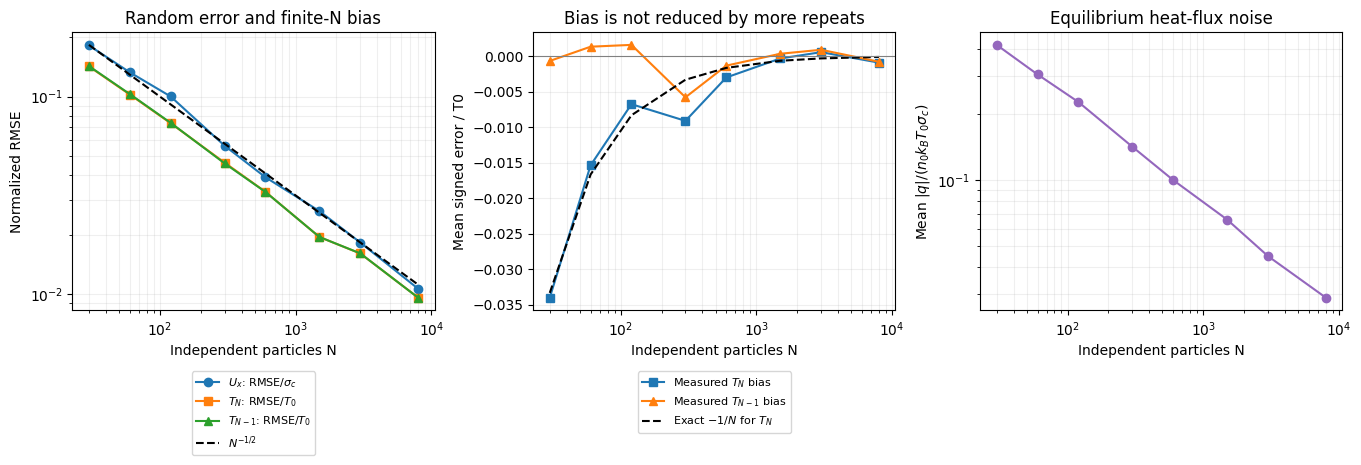

In [6]:

# Dimensionless errors allow a meaningful comparison of different moments.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), layout="constrained")
N = noise_df["N"].to_numpy()
axes[0].loglog(N, noise_df["rmse_Ux"]/sigma_true, "o-", label=r"$U_x$: RMSE/$\sigma_c$")
axes[0].loglog(N, noise_df["rmse_T"]/T_TRUE, "s-", label=r"$T_N$: RMSE/$T_0$")
axes[0].loglog(N, noise_df["rmse_T_unbiased"]/T_TRUE, "^-", label=r"$T_{N-1}$: RMSE/$T_0$")
axes[0].loglog(N, N.astype(float)**(-.5), "k--", label=r"$N^{-1/2}$")
axes[0].set(xlabel="Independent particles N", ylabel="Normalized RMSE", title="Random error and finite-N bias")
axes[1].semilogx(N, noise_df["bias_T"]/T_TRUE, "s-", label=r"Measured $T_N$ bias")
axes[1].semilogx(N, noise_df["bias_T_unbiased"]/T_TRUE, "^-", label=r"Measured $T_{N-1}$ bias")
axes[1].semilogx(N, -1/N, "k--", label=r"Exact $-1/N$ for $T_N$")
axes[1].axhline(0, color=".5", lw=.8)
axes[1].set(xlabel="Independent particles N", ylabel="Mean signed error / T0", title="Bias is not reduced by more repeats")
axes[2].loglog(N, noise_df["mean_qstar_norm"], "o-", color="tab:purple")
axes[2].set(xlabel="Independent particles N", ylabel=r"Mean $|q|/(n_0k_BT_0\sigma_c)$", title="Equilibrium heat-flux noise")
for ax in axes: ax.grid(which="both", alpha=.2)
for ax in axes[:2]: ax.legend(loc="upper center", bbox_to_anchor=(.5,-.20), fontsize=8)
plt.show()


### Report prompt 3
Report both fitted slopes. If the effective number of independent samples increases by a factor of 100, predict the approximate error reduction. Explain why time-correlated DSMC samples may have fewer independent samples than the raw sample count suggests.

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 4. ML bridge: the network learns the labels it receives

The smooth slip curve below is an **analytic teaching proxy**, not a solution of the Boltzmann equation. Both networks receive the same 75 condition coordinates and have identical architecture, initialization and L-BFGS settings. Only label quality changes. `StandardScaler` is fit to the training coordinates; tanh layers map that coordinate to one scalar output, and L-BFGS uses gradients of squared label error with an L2 weight penalty.

The long-averaging labels use a smaller prescribed noise amplitude. This mimics a data-quality improvement but is not a measured DSMC averaging law. Noise is clipped at zero, which can bias observations near zero. A flexible network can interpolate noise or violate monotonicity even when its curve looks smooth. Plot signed error against the known analytic proxy and retain any optimizer warning; do not call the noisier-label model a failed physical solver.


In [7]:
def hidden_slip_trend(log10_kn):
    """A smooth teaching target used only to expose the effect of noisy labels."""
    kn = 10.0**np.asarray(log10_kn)
    return 0.04 + 0.82*kn/(kn + 0.08)


log_kn_train = np.linspace(-3.0, 1.0, 75)
y_truth_train = hidden_slip_trend(log_kn_train)
label_rng = np.random.default_rng(18)

# Short averaging produces noisier labels; long averaging produces cleaner labels.
noise_short = 0.075*(1.0 + 0.25*(log_kn_train+3.0)/4.0)
noise_long = 0.018*(1.0 + 0.25*(log_kn_train+3.0)/4.0)
y_short = np.clip(y_truth_train + label_rng.normal(0.0, noise_short), 0.0, None)
y_long = np.clip(y_truth_train + label_rng.normal(0.0, noise_long), 0.0, None)


HIDDEN_UNITS = (24, 24)
ACTIVATION = "tanh"
MLP_ALPHA = 1e-3
MAX_ITER = 3000
MLP_SEED = 4

def make_small_mlp(random_state=MLP_SEED):
    return make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=HIDDEN_UNITS, activation=ACTIVATION, solver="lbfgs",
                     alpha=MLP_ALPHA, max_iter=MAX_ITER, random_state=random_state)
    )

model_short = make_small_mlp()
model_long = make_small_mlp()
model_short.fit(log_kn_train[:, None], y_short)
model_long.fit(log_kn_train[:, None], y_long)

log_kn_test = np.linspace(-3.0, 1.0, 400)
y_truth_test = hidden_slip_trend(log_kn_test)
pred_short = model_short.predict(log_kn_test[:, None])
pred_long = model_long.predict(log_kn_test[:, None])

rmse_short = np.sqrt(mean_squared_error(y_truth_test, pred_short))
rmse_long = np.sqrt(mean_squared_error(y_truth_test, pred_long))
print(f"RMSE vs hidden truth, short averaging labels: {rmse_short:.4f}")
print(f"RMSE vs hidden truth, long  averaging labels: {rmse_long:.4f}")

RMSE vs hidden truth, short averaging labels: 0.0261
RMSE vs hidden truth, long  averaging labels: 0.0100


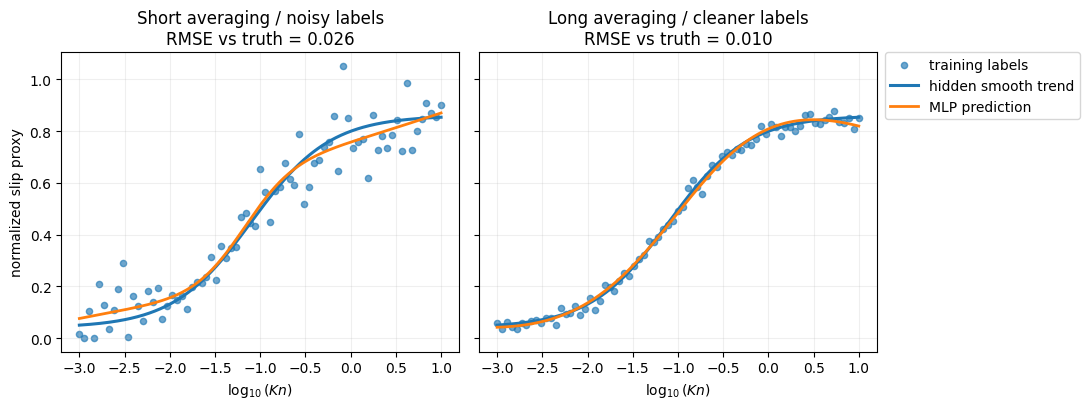

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, labels, prediction, title, rmse in [
    (axes[0], y_short, pred_short, "Short averaging / noisy labels", rmse_short),
    (axes[1], y_long, pred_long, "Long averaging / cleaner labels", rmse_long),
]:
    ax.scatter(log_kn_train, labels, s=20, alpha=0.65, label="training labels")
    ax.plot(log_kn_test, y_truth_test, lw=2.2, label="hidden smooth trend")
    ax.plot(log_kn_test, prediction, lw=2, label="MLP prediction")
    ax.set_xlabel(r"$\log_{10}(Kn)$")
    ax.set_title(f"{title}\nRMSE vs truth = {rmse:.3f}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("normalized slip proxy")
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

In [9]:
# Basic physical checks on the two learned curves.
def monotonicity_violations(y):
    return int(np.sum(np.diff(y) < 0.0))

ml_checks = pd.DataFrame({
    "training-label quality": ["short averaging", "long averaging"],
    "RMSE vs hidden truth": [rmse_short, rmse_long],
    "negative predictions": [int(np.sum(pred_short < 0)), int(np.sum(pred_long < 0))],
    "monotonicity violations": [monotonicity_violations(pred_short), monotonicity_violations(pred_long)]
})
display(ml_checks)

,training-label quality,RMSE vs hidden truth,negative predictions,monotonicity violations
0,short averaging,0.026127,0,0
1,long averaging,0.009988,0,50


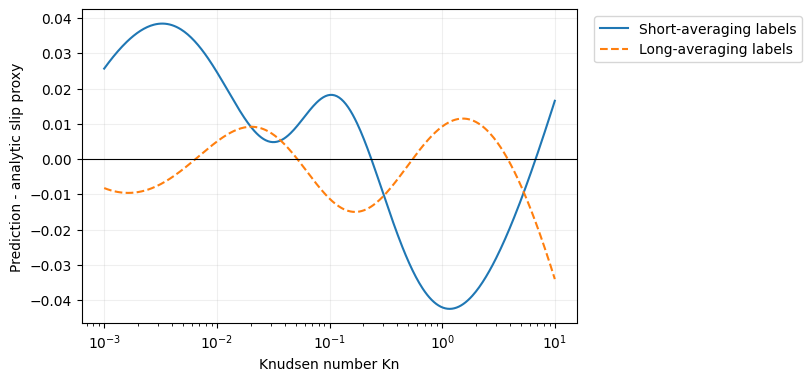

L-BFGS accepted iterations: 46 15


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.plot(10**log_kn_test, pred_short-y_truth_test, label="Short-averaging labels")
ax.plot(10**log_kn_test, pred_long-y_truth_test, label="Long-averaging labels", ls="--")
ax.axhline(0, color="black", lw=.8)
ax.set(xscale="log", xlabel="Knudsen number Kn", ylabel="Prediction - analytic slip proxy")
ax.legend(loc="upper left", bbox_to_anchor=(1.02,1)); ax.grid(alpha=.2); plt.show()
print("L-BFGS accepted iterations:", model_short[-1].n_iter_, model_long[-1].n_iter_)


### Report prompt 4
Which model is closer to the hidden trend? Does a smooth prediction or low training loss prove that the original DSMC labels were converged? What data-quality metadata should accompany future DSMC training data?

> **Your response:** Write a concise answer here for your own record, and include the final version in the PDF report.
>
> ...

## 5. Save tables used in the report

In [11]:
noise_df.to_csv("week3_lab1_sampling_noise.csv", index=False)
ml_checks.to_csv("week3_lab1_ml_noise_checks.csv", index=False)
print("Saved week3_lab1_sampling_noise.csv")
print("Saved week3_lab1_ml_noise_checks.csv")

Saved week3_lab1_sampling_noise.csv
Saved week3_lab1_ml_noise_checks.csv


### Three controlled investigations to submit

1. **Bias versus variability:** at N=30,60,300 report the mean signed temperature error and RMSE for both denominators. Compare the measured mean with $-T_0/N$. Repeat with twice as many independent clouds. Explain why a noisy estimate of bias can fluctuate around its exact expectation.
2. **Signal-to-noise:** keep temperature fixed and reduce the imposed x drift from100 to10 m/s. Compare the absolute drift standard error with its value relative to the drift. Do not divide by a zero velocity component. Explain why low-speed molecular flow is costly even when the thermal distribution is well sampled.
3. **Data quality versus model capacity:** retain the default fit, then change only one width/depth control. Report iteration counts, signed error and monotonicity violations for each noise level. State whether the change learned a useful trend or fit noisy labels more closely. A new validation design is required before presenting a tuned result as an independent test.


## Final checklist for Lab 1
- [ ] Notebook runs from top to bottom.
- [ ] All plots and tables remain visible.
- [ ] Fitted noise slopes are reported in the PDF.
- [ ] Heat-flux noise is interpreted.
- [ ] The noisy-label ML comparison is discussed.
- [ ] The final written answers appear in the PDF report.

## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).


<!-- FLOWMLLAB_EARLY_TEACHING_20261120 -->
